# 01 — Data Audit

This notebook explores the structure,
 metadata, spatial properties, and values of the Global Human Modification dataset before visualization or analysis.

In [1]:
import sys

import geopandas as gpd
import rasterio
import rioxarray
import xarray as xr
import pydeck as pdk
import matplotlib.pyplot as plt

print("Python executable:", sys.executable)
print()
print("GeoPandas:", gpd.__version__)
print("Rasterio:", rasterio.__version__)
print("rioxarray:", rioxarray.__version__)
print("xarray:", xr.__version__)
print("PyDeck:", pdk.__version__)
print("Matplotlib:", plt.matplotlib.__version__)

Python executable: c:\Users\ynalq\anaconda3\envs\human-modification-atlas\python.exe

GeoPandas: 1.1.4
Rasterio: 1.4.4
rioxarray: 0.19.0
xarray: 2026.7.0
PyDeck: 0.9.3
Matplotlib: 3.11.1


In [2]:
import numpy as np

human_modification = np.array([
    [0.01, 0.03, 0.08, 0.12, 0.20],
    [0.02, 0.05, 0.15, 0.35, 0.55],
    [0.01, 0.08, 0.30, 0.65, 0.85],
    [0.00, 0.04, 0.18, 0.72, 0.95]
])

print(human_modification)
print()
print("Shape:", human_modification.shape)
print("Data type:", human_modification.dtype)
print("Minimum:", human_modification.min())
print("Maximum:", human_modification.max())

[[0.01 0.03 0.08 0.12 0.2 ]
 [0.02 0.05 0.15 0.35 0.55]
 [0.01 0.08 0.3  0.65 0.85]
 [0.   0.04 0.18 0.72 0.95]]

Shape: (4, 5)
Data type: float64
Minimum: 0.0
Maximum: 0.95


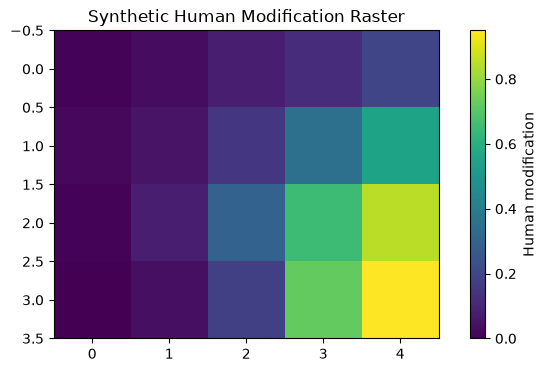

In [3]:
plt.figure(figsize=(8, 4))

plt.imshow(human_modification)
plt.colorbar(label="Human modification")
plt.title("Synthetic Human Modification Raster")

plt.show()

## Georeferencing a Raster

A numerical raster becomes geospatial when its cells are connected to real-world coordinates through a coordinate reference system, spatial resolution, and affine transform.

In [4]:
from rasterio.transform import from_origin
from rasterio.transform import array_bounds

# Pretend our raster starts at longitude -10°, latitude 50°
# and each pixel represents 1° × 1°
transform = from_origin(
    west=-10,
    north=50,
    xsize=0.5,
    ysize=0.5
)

height, width = human_modification.shape

bounds = array_bounds(
    height,
    width,
    transform
)

print("Raster shape:", human_modification.shape)
print("Transform:")
print(transform)
print()
print("Bounds:", bounds)

Raster shape: (4, 5)
Transform:
| 0.50, 0.00,-10.00|
| 0.00,-0.50, 50.00|
| 0.00, 0.00, 1.00|

Bounds: (-10.0, 48.0, -7.5, 50.0)


In [5]:
crs = "EPSG:4326"

print("CRS:", crs)

CRS: EPSG:4326


In [6]:
from rasterio.transform import xy

x, y = xy(transform, 0, 0)

print("Center of pixel [0, 0]:")
print("Longitude:", x)
print("Latitude:", y)

Center of pixel [0, 0]:
Longitude: -9.75
Latitude: 49.75


## Real Dataset Audit — Natural System Modification

The first real raster inspected in this project is the Natural System Modification (`NS`) layer from the 2022 static Global Human Modification product at 300 m resolution.

The goal of this section is to inspect the raster metadata and spatial properties before performing any analysis or visualization.

In [7]:
from pathlib import Path

data_path = Path("../data/raw/HMv20240801_2022s_NS_300.tif")

print("File:", data_path)
print("Exists:", data_path.exists())

File: ..\data\raw\HMv20240801_2022s_NS_300.tif
Exists: True


In [8]:
with rasterio.open(data_path) as src:
    print("Driver:", src.driver)
    print("Width:", src.width)
    print("Height:", src.height)
    print("Bands:", src.count)
    print("Data type:", src.dtypes)
    print("CRS:", src.crs)
    print("Resolution:", src.res)
    print("Bounds:", src.bounds)
    print("NoData:", src.nodata)
    print()
    print("Transform:")
    print(src.transform)

Driver: GTiff
Width: 133584
Height: 66792
Bands: 1
Data type: ('float32',)
CRS: EPSG:4326
Resolution: (0.0026949458523585646, 0.0026949458523585646)
Bounds: BoundingBox(left=-180.00082337073326, bottom=-90.00041168536663, right=180.00082337073326, top=90.00041168536663)
NoData: None

Transform:
| 0.00, 0.00,-180.00|
| 0.00,-0.00, 90.00|
| 0.00, 0.00, 1.00|


In [9]:
with rasterio.open(data_path) as src:
    print(repr(src.transform))

Affine(0.0026949458523585646, 0.0, -180.00082337073326,
       0.0, -0.0026949458523585646, 90.00041168536663)


## Windowed Reading

The full raster contains billions of cells and is too large to load into memory safely. Rasterio windows allow only a selected subset of pixels to be read.

In [10]:
from rasterio.windows import Window

window = Window(
    col_off=66000,
    row_off=33000,
    width=512,
    height=512
)

with rasterio.open(data_path) as src:
    sample = src.read(1, window=window)

print("Sample shape:", sample.shape)
print("Data type:", sample.dtype)
print("Minimum:", sample.min())
print("Maximum:", sample.max())
print("Mean:", sample.mean())

Sample shape: (512, 512)
Data type: float32
Minimum: nan
Maximum: nan
Mean: nan


In [11]:
import numpy as np

print("Total pixels:", sample.size)
print("NaN pixels:", np.isnan(sample).sum())
print("Valid pixels:", np.isfinite(sample).sum())

print()
print("Valid fraction:", np.isfinite(sample).mean())

Total pixels: 262144
NaN pixels: 262144
Valid pixels: 0

Valid fraction: 0.0


In [12]:
print("Minimum:", np.nanmin(sample))
print("Maximum:", np.nanmax(sample))
print("Mean:", np.nanmean(sample))

Minimum: nan
Maximum: nan
Mean: nan


C:\Users\ynalq\AppData\Local\Temp\ipykernel_1588\2996604038.py:1: RuntimeWarning: All-NaN slice encountered
  print("Minimum:", np.nanmin(sample))
C:\Users\ynalq\AppData\Local\Temp\ipykernel_1588\2996604038.py:2: RuntimeWarning: All-NaN slice encountered
  print("Maximum:", np.nanmax(sample))
C:\Users\ynalq\AppData\Local\Temp\ipykernel_1588\2996604038.py:3: RuntimeWarning: Mean of empty slice
  print("Mean:", np.nanmean(sample))


In [13]:
valid = sample[np.isfinite(sample)]

print("Valid pixels:", valid.size)

if valid.size > 0:
    print("Minimum:", valid.min())
    print("Maximum:", valid.max())
    print("Mean:", valid.mean())
else:
    print("No valid pixels in this window.")

Valid pixels: 0
No valid pixels in this window.


In [14]:
with rasterio.open(data_path) as src:
    row, col = src.index(10.0, 51.0)

print("Row:", row)
print("Column:", col)

Row: 14471
Column: 70502


In [15]:
with rasterio.open(data_path) as src:
    row, col = src.index(10.0, 51.0)

    size = 512

    window = Window(
        col_off=col - size // 2,
        row_off=row - size // 2,
        width=size,
        height=size
    )

    germany_sample = src.read(1, window=window)

valid = germany_sample[np.isfinite(germany_sample)]

print("Shape:", germany_sample.shape)
print("Valid pixels:", valid.size)
print("Valid fraction:", np.isfinite(germany_sample).mean())

if valid.size > 0:
    print("Minimum:", valid.min())
    print("Maximum:", valid.max())
    print("Mean:", valid.mean())

Shape: (512, 512)
Valid pixels: 262144
Valid fraction: 1.0
Minimum: 0.0
Maximum: 0.78
Mean: 0.00011675582


## Value Distribution

Before visualizing the spatial pattern, the distribution of valid raster values is inspected to understand how sparse or skewed the Natural System Modification layer is.

In [16]:
valid_mask = np.isfinite(germany_sample)

valid_values = germany_sample[valid_mask]
positive_values = valid_values[valid_values > 0]

zero_count = np.sum(valid_values == 0)

print("Valid pixels:", valid_values.size)
print("Zero-value pixels:", zero_count)
print("Positive-value pixels:", positive_values.size)

print()
print("Zero fraction:", zero_count / valid_values.size)
print("Positive fraction:", positive_values.size / valid_values.size)

Valid pixels: 262144
Zero-value pixels: 262062
Positive-value pixels: 82

Zero fraction: 0.9996871948242188
Positive fraction: 0.00031280517578125


In [17]:
if positive_values.size > 0:
    print("Positive minimum:", positive_values.min())
    print("Positive median:", np.median(positive_values))
    print("Positive mean:", positive_values.mean())
    print("90th percentile:", np.quantile(positive_values, 0.90))
    print("99th percentile:", np.quantile(positive_values, 0.99))
    print("Maximum:", positive_values.max())

Positive minimum: 0.013607521
Positive median: 0.28603202
Positive mean: 0.37325412
90th percentile: 0.748773
99th percentile: 0.78
Maximum: 0.78


In [18]:
from rasterio.windows import bounds as window_bounds

with rasterio.open(data_path) as src:
    germany_bounds = window_bounds(window, src.transform)

print("Window bounds:", germany_bounds)

Window bounds: (9.308342974046468, 50.311944117682046, 10.68815525045406, 51.69175639408963)


## Spatial Visualization of the Sample Window

The raster window is visualized using its geographic bounds so that the image axes represent longitude and latitude rather than array row and column indices.

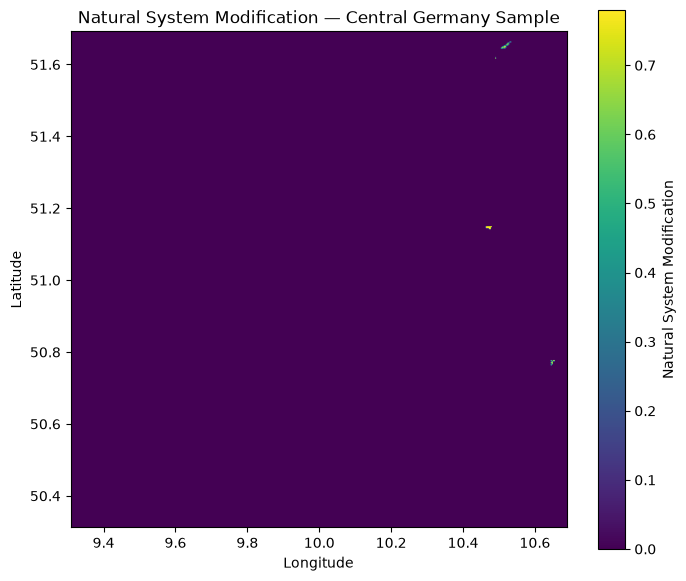

In [19]:
left, bottom, right, top = germany_bounds

plt.figure(figsize=(8, 7))

plt.imshow(
    germany_sample,
    extent=(left, right, bottom, top),
    origin="upper"
)

plt.colorbar(label="Natural System Modification")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Natural System Modification — Central Germany Sample")

plt.show()

### Interpretation

The Natural System Modification (`NS`) layer represents one specific category of human pressure, focused primarily on dams and reservoirs. Its sparse distribution in the central Germany sample therefore does not represent total human modification.

The `NS` raster was used primarily to learn raster metadata inspection, windowed reading, coordinate-to-pixel conversion, missing-value handling, and basic geospatial visualization.

The subsequent analysis uses the `AA` (`All Threats Combined`) layer to investigate cumulative human modification.

## Remote Cloud-Optimized GeoTIFF Access

The `AA` layer combines all modeled human-modification threats and is the primary layer used for the overall analysis.

Because the global 2022 raster is approximately 9.3 GB, it is accessed remotely as a Cloud-Optimized GeoTIFF rather than downloaded and loaded entirely into memory.

In [20]:
aa_url = (
    "https://zenodo.org/records/14502573/files/"
    "HMv20240801_2022s_AA_300.tif?download=1"
)

print(aa_url)

https://zenodo.org/records/14502573/files/HMv20240801_2022s_AA_300.tif?download=1


In [21]:
with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"):
    with rasterio.open(aa_url) as src:
        print("Driver:", src.driver)
        print("Width:", src.width)
        print("Height:", src.height)
        print("Bands:", src.count)
        print("Data type:", src.dtypes)
        print("CRS:", src.crs)
        print("Resolution:", src.res)
        print("Bounds:", src.bounds)
        print("NoData:", src.nodata)

Driver: GTiff
Width: 133584
Height: 66792
Bands: 1
Data type: ('float32',)
CRS: EPSG:4326
Resolution: (0.0026949458523585646, 0.0026949458523585646)
Bounds: BoundingBox(left=-180.00082337073326, bottom=-90.00041168536663, right=180.00082337073326, top=90.00041168536663)
NoData: None


In [22]:
with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"):
    with rasterio.open(aa_url) as src:
        print("Block shapes:", src.block_shapes)
        print("Overviews:", src.overviews(1))

Block shapes: [(256, 256)]
Overviews: [2, 4, 8, 16, 32]


## All-Threats-Combined Sample

The `AA` (`All Threats Combined`) layer is sampled over the same central Germany location used for the `NS` layer. Because both rasters share the same CRS, resolution, dimensions, and geographic extent, the samples are spatially comparable.

In [23]:
from rasterio.windows import Window

with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"):
    with rasterio.open(aa_url) as src:

        # Central Germany
        row, col = src.index(10.0, 51.0)

        size = 512

        aa_window = Window(
            col_off=col - size // 2,
            row_off=row - size // 2,
            width=size,
            height=size
        )

        aa_sample = src.read(1, window=aa_window)

print("Center row:", row)
print("Center column:", col)
print("Shape:", aa_sample.shape)
print("Data type:", aa_sample.dtype)

Center row: 14471
Center column: 70502
Shape: (512, 512)
Data type: float32


In [24]:
aa_valid = aa_sample[np.isfinite(aa_sample)]

print("Total pixels:", aa_sample.size)
print("NaN pixels:", np.isnan(aa_sample).sum())
print("Valid pixels:", aa_valid.size)

print()

if aa_valid.size > 0:
    print("Minimum:", aa_valid.min())
    print("Maximum:", aa_valid.max())
    print("Mean:", aa_valid.mean())
    print("Median:", np.median(aa_valid))
    print("10th percentile:", np.quantile(aa_valid, 0.10))
    print("25th percentile:", np.quantile(aa_valid, 0.25))
    print("75th percentile:", np.quantile(aa_valid, 0.75))
    print("90th percentile:", np.quantile(aa_valid, 0.90))

Total pixels: 262144
NaN pixels: 351
Valid pixels: 261793

Minimum: 0.01582576
Maximum: 1.0
Mean: 0.4072783
Median: 0.39542136
10th percentile: 0.10439305
25th percentile: 0.1590542
75th percentile: 0.56016004
90th percentile: 0.79797596


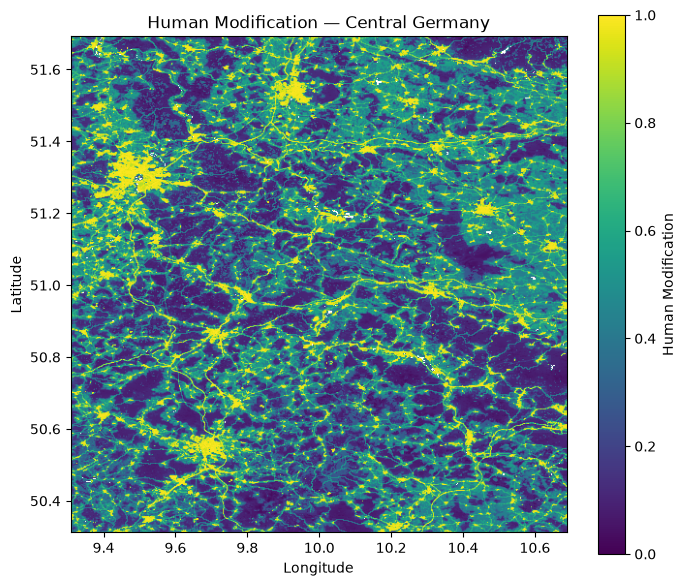

In [25]:
from rasterio.windows import bounds as window_bounds

with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"):
    with rasterio.open(aa_url) as src:
        aa_bounds = window_bounds(aa_window, src.transform)

left, bottom, right, top = aa_bounds

plt.figure(figsize=(8, 7))

plt.imshow(
    aa_sample,
    extent=(left, right, bottom, top),
    origin="upper",
    vmin=0,
    vmax=1
)

plt.colorbar(label="Human Modification")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Human Modification — Central Germany")

plt.show()

## Human Modification Classes

The continuous Human Modification values are grouped into the published modification classes to make spatial patterns easier to interpret:

- Very low: H < 0.01
- Low: 0.01 ≤ H < 0.10
- Moderate: 0.10 ≤ H < 0.40
- High: 0.40 ≤ H ≤ 0.70
- Very high: H > 0.70

In [26]:
import pandas as pd

valid_mask = np.isfinite(aa_sample)
total_valid = valid_mask.sum()

classes = {
    "Very low": valid_mask & (aa_sample < 0.01),
    "Low": valid_mask & (aa_sample >= 0.01) & (aa_sample < 0.10),
    "Moderate": valid_mask & (aa_sample >= 0.10) & (aa_sample < 0.40),
    "High": valid_mask & (aa_sample >= 0.40) & (aa_sample <= 0.70),
    "Very high": valid_mask & (aa_sample > 0.70),
}

classification_rows = []

for class_name, mask in classes.items():
    count = mask.sum()
    percentage = count / total_valid * 100

    classification_rows.append({
        "Class": class_name,
        "Pixels": count,
        "Percentage": percentage
    })

classification_df = pd.DataFrame(classification_rows)

classification_df

,Class,Pixels,Percentage
0,Very low,0,0.000000
1,Low,21428,8.185093
2,Moderate,111227,42.486621
3,High,93729,35.802714
4,Very high,35409,13.525572


In [27]:
print("Classified pixels:", classification_df["Pixels"].sum())
print("Valid pixels:", total_valid)
print("Percentage sum:", classification_df["Percentage"].sum())

Classified pixels: 261793
Valid pixels: 261793
Percentage sum: 100.0


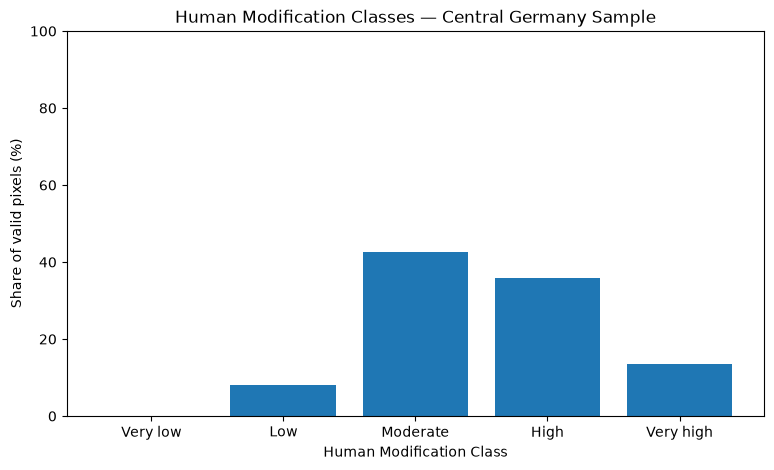

In [28]:
plt.figure(figsize=(9, 5))

plt.bar(
    classification_df["Class"],
    classification_df["Percentage"]
)

plt.ylabel("Share of valid pixels (%)")
plt.xlabel("Human Modification Class")
plt.title("Human Modification Classes — Central Germany Sample")
plt.ylim(0, 100)

plt.show()

## Global Downsampled Analysis

The full-resolution `AA` raster contains approximately 8.9 billion pixels and is unnecessary for global-scale visualization.

A lower-resolution representation is therefore read from the Cloud-Optimized GeoTIFF using its overview pyramid. This preserves the original dataset while reducing the amount of data required for exploratory global visualization.

### Initial Arbitrary Downsample

A 4096 × 2048 output size is first used as a manually selected global visualization resolution.

In [29]:
from rasterio.enums import Resampling
import time

target_width = 4096
target_height = 2048

with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"):
    with rasterio.open(aa_url) as src:

        start = time.perf_counter()

        aa_global = src.read(
            1,
            out_shape=(target_height, target_width),
            resampling=Resampling.nearest
        )

        elapsed = time.perf_counter() - start
        global_bounds = src.bounds

print("Original shape:", (66792, 133584))
print("Downsampled shape:", aa_global.shape)
print("Data type:", aa_global.dtype)
print("Memory:", aa_global.nbytes / 1024**2, "MB")
print("Read time:", elapsed, "seconds")

Original shape: (66792, 133584)
Downsampled shape: (2048, 4096)
Data type: float32
Memory: 32.0 MB
Read time: 18.95586430002004 seconds


In [30]:
global_valid = aa_global[np.isfinite(aa_global)]

print("Total pixels:", aa_global.size)
print("NaN pixels:", np.isnan(aa_global).sum())
print("Valid pixels:", global_valid.size)

print()

print("Minimum:", global_valid.min())
print("Maximum:", global_valid.max())
print("Mean:", global_valid.mean())
print("Median:", np.median(global_valid))

Total pixels: 8388608
NaN pixels: 6452384
Valid pixels: 1936224

Minimum: 0.0
Maximum: 1.0
Mean: 0.10229826
Median: 0.008610354


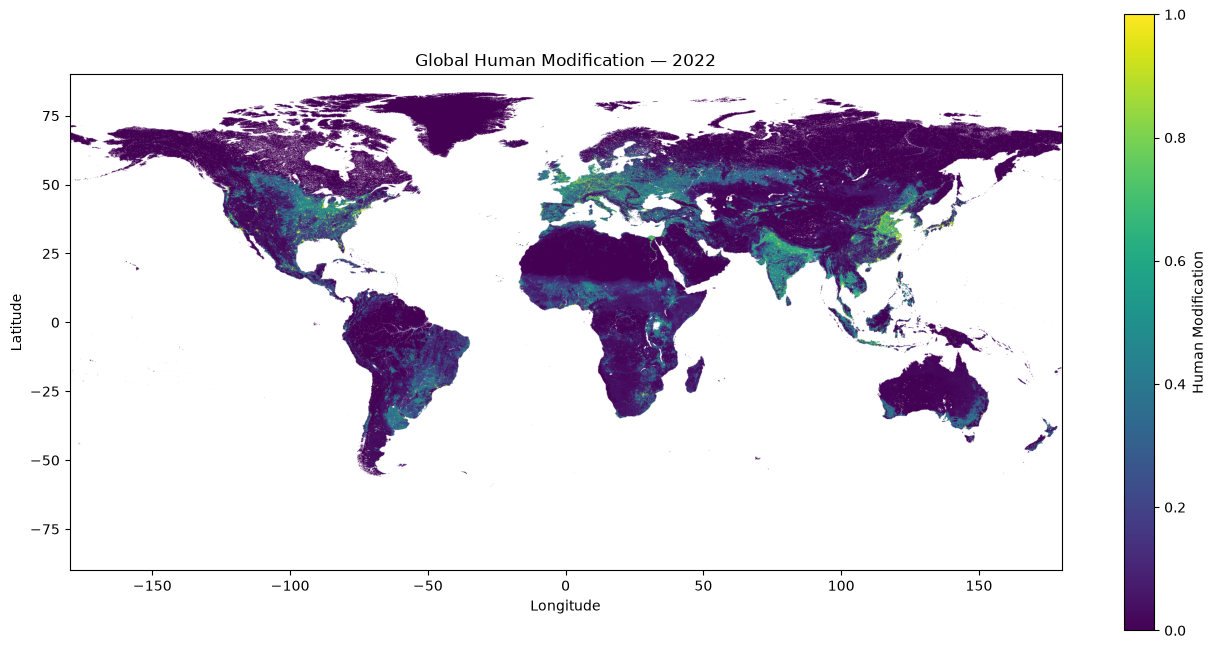

In [31]:
masked_global = np.ma.masked_invalid(aa_global)

plt.figure(figsize=(16, 8))

plt.imshow(
    masked_global,
    extent=(
        global_bounds.left,
        global_bounds.right,
        global_bounds.bottom,
        global_bounds.top
    ),
    origin="upper",
    vmin=0,
    vmax=1
)

plt.colorbar(label="Human Modification")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title("Global Human Modification — 2022")

plt.show()

### Overview-Aware Downsample

The COG overview pyramid is inspected and the coarsest available overview factor is used to derive an output resolution from the source dataset itself.

The global Human Modification raster is visualized at a resolution derived from the coarsest available COG overview (`32×`).

The source raster remains unchanged; this representation sacrifices local spatial detail in exchange for efficient global-scale exploration.

In [32]:
from math import ceil
from rasterio.enums import Resampling
import time

with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"):
    with rasterio.open(aa_url) as src:

        factors = src.overviews(1)
        factor = factors[-1]

        target_width = ceil(src.width / factor)
        target_height = ceil(src.height / factor)

        print("Original shape:", (src.height, src.width))
        print("Available overviews:", factors)
        print("Selected factor:", factor)
        print("Target shape:", (target_height, target_width))

        start = time.perf_counter()

        aa_global_overview = src.read(
            1,
            out_shape=(target_height, target_width),
            resampling=Resampling.nearest
        )

        elapsed = time.perf_counter() - start
        global_bounds = src.bounds

print()
print("Read shape:", aa_global_overview.shape)
print("Data type:", aa_global_overview.dtype)
print("Memory:", aa_global_overview.nbytes / 1024**2, "MB")
print("Read time:", elapsed, "seconds")

Original shape: (66792, 133584)
Available overviews: [2, 4, 8, 16, 32]
Selected factor: 32
Target shape: (2088, 4175)

Read shape: (2088, 4175)
Data type: float32
Memory: 33.254241943359375 MB
Read time: 18.74118280003313 seconds


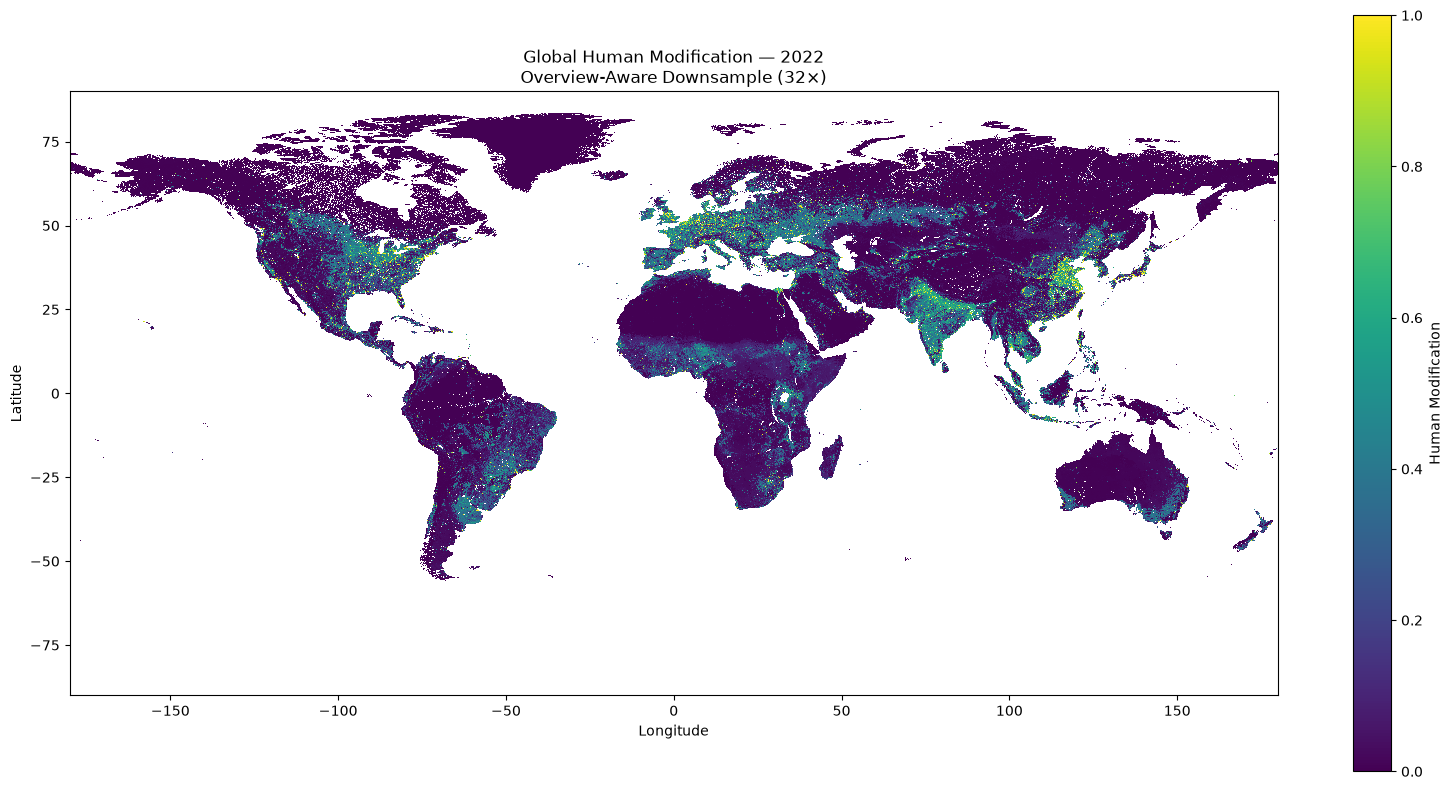

In [33]:
masked_global_overview = np.ma.masked_invalid(aa_global_overview)

plt.figure(figsize=(16, 8))

plt.imshow(
    masked_global_overview,
    extent=(
        global_bounds.left,
        global_bounds.right,
        global_bounds.bottom,
        global_bounds.top
    ),
    origin="upper",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

plt.colorbar(label="Human Modification")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(
    "Global Human Modification — 2022\n"
    "Overview-Aware Downsample (32×)"
)

plt.tight_layout()
plt.show()

In [34]:
print("Arbitrary NaNs:", np.isnan(aa_global).sum())
print(
    "Arbitrary NaN %:",
    np.isnan(aa_global).mean() * 100
)

print()

print("Overview-aware NaNs:", np.isnan(aa_global_overview).sum())
print(
    "Overview-aware NaN %:",
    np.isnan(aa_global_overview).mean() * 100
)

Arbitrary NaNs: 6452384
Arbitrary NaN %: 76.91841125488281

Overview-aware NaNs: 6705563
Overview-aware NaN %: 76.92159359442036


In [35]:
with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"):
    with rasterio.open(aa_url) as src:
        print("NoData:", src.nodata)
        print("Mask flags:", src.mask_flag_enums)

NoData: None
Mask flags: ([<MaskFlags.all_valid: 1>],)


### Resampling Experiment: Nearest Neighbour vs. Average

Downsampling requires multiple high-resolution source pixels to be represented by fewer output pixels. The chosen resampling method therefore affects both the resulting values and the visual appearance of the global raster.

Two approaches are compared:

- **Nearest neighbour** selects a representative source value without averaging neighboring cells.
- **Average resampling** summarizes the contributing source pixels using their mean value, which can be more appropriate for a continuous variable such as Human Modification.

The comparison also examines missing-value behavior. The source GeoTIFF contains floating-point `NaN` values, but does not declare a formal GDAL NoData value or validity mask. This may affect how different resampling algorithms treat missing cells.

Both methods are evaluated using the same overview-derived output dimensions so that differences are attributable to the resampling method rather than the target grid.

In [36]:
aa_global_nearest = aa_global_overview

In [37]:
from rasterio.enums import Resampling
import time

with rasterio.Env(GDAL_DISABLE_READDIR_ON_OPEN="EMPTY_DIR"):
    with rasterio.open(aa_url) as src:

        start = time.perf_counter()

        aa_global_average = src.read(
            1,
            out_shape=(target_height, target_width),
            resampling=Resampling.average
        )

        average_elapsed = time.perf_counter() - start

print("Shape:", aa_global_average.shape)
print("Memory:", aa_global_average.nbytes / 1024**2, "MB")
print("Read time:", average_elapsed, "seconds")

Shape: (2088, 4175)
Memory: 33.254241943359375 MB
Read time: 20.566853900032584 seconds


In [38]:
nearest_valid = np.isfinite(aa_global_nearest)
average_valid = np.isfinite(aa_global_average)

print("Nearest NaN %:", (~nearest_valid).mean() * 100)
print("Average NaN %:", (~average_valid).mean() * 100)

print()
print(
    "Valid in both:",
    np.sum(nearest_valid & average_valid)
)

print(
    "Nearest valid, average NaN:",
    np.sum(nearest_valid & ~average_valid)
)

print(
    "Nearest NaN, average valid:",
    np.sum(~nearest_valid & average_valid)
)

print(
    "NaN in both:",
    np.sum(~nearest_valid & ~average_valid)
)

Nearest NaN %: 76.92159359442036
Average NaN %: 78.63405373161723

Valid in both: 1862555
Nearest valid, average NaN: 149282
Nearest NaN, average valid: 0
NaN in both: 6705563


In [39]:
both_valid = nearest_valid & average_valid

difference = np.abs(
    aa_global_nearest[both_valid]
    - aa_global_average[both_valid]
)

print("Mean absolute difference:", difference.mean())
print("Median absolute difference:", np.median(difference))
print("90th percentile difference:", np.quantile(difference, 0.90))
print("Maximum difference:", difference.max())

Mean absolute difference: 0.030311894
Median absolute difference: 0.0021941913
90th percentile difference: 0.10076582
Maximum difference: 0.6882474


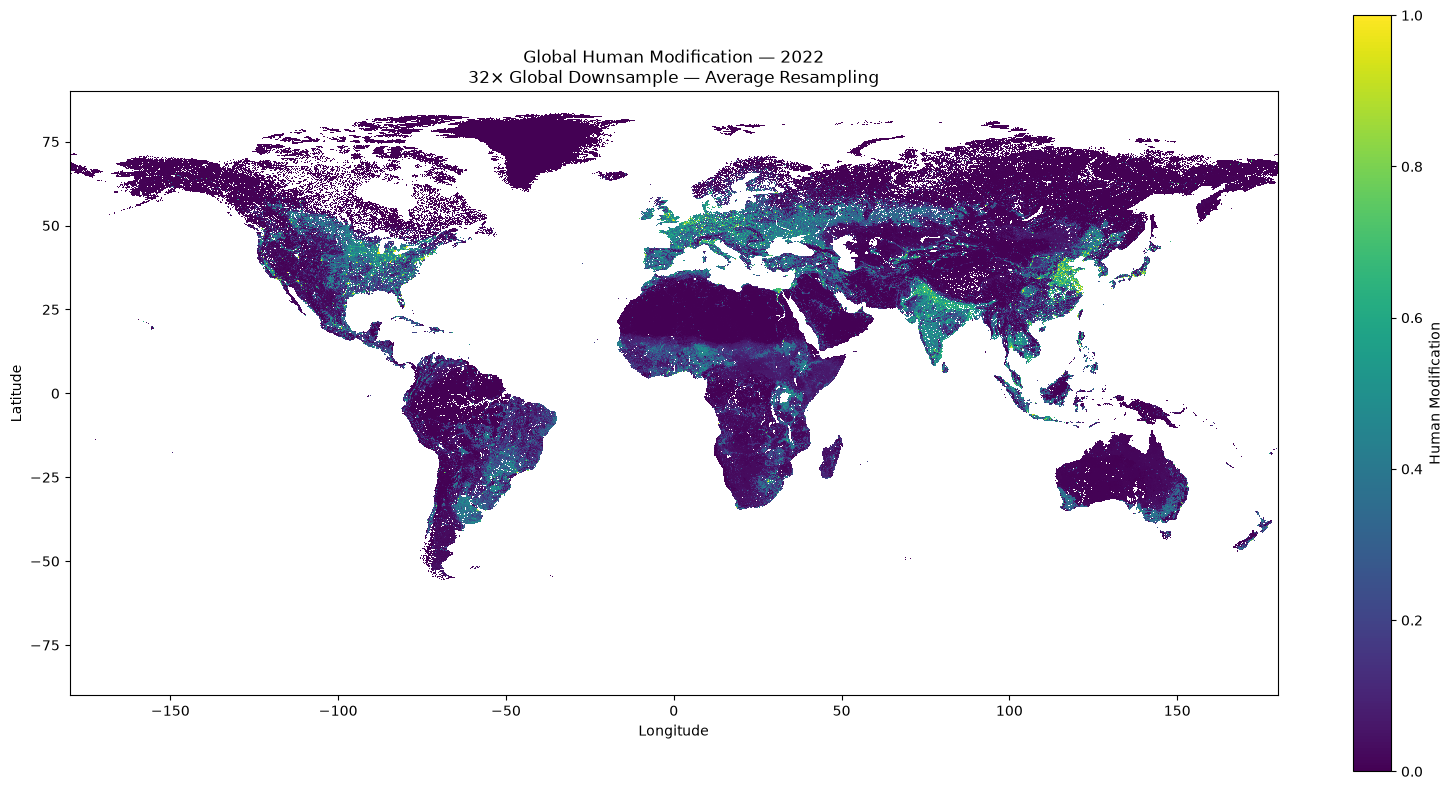

In [40]:
masked_global_average = np.ma.masked_invalid(aa_global_average)

plt.figure(figsize=(16, 8))

plt.imshow(
    masked_global_average,
    extent=(
        global_bounds.left,
        global_bounds.right,
        global_bounds.bottom,
        global_bounds.top
    ),
    origin="upper",
    vmin=0,
    vmax=1,
    interpolation="nearest"
)

plt.colorbar(label="Human Modification")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.title(
    "Global Human Modification — 2022\n"
    "32× Global Downsample — Average Resampling"
)

plt.tight_layout()
plt.show()

#### Interpretation

Nearest-neighbour and average resampling preserve broadly similar global patterns, but their treatment of missing values differs substantially.

Average resampling produced a larger proportion of `NaN` cells. Approximately 149,000 pixels that were valid under nearest-neighbour resampling became `NaN` under average resampling, while no cells showed the reverse behavior.

This is consistent with the source raster containing floating-point `NaN` values without a formally declared NoData value. Because those cells are not identified as NoData in the raster metadata, they may propagate through an averaging operation rather than being excluded from it.

For pixels valid under both approaches, the median absolute difference was small, although larger differences occurred in heterogeneous areas.

Before average resampling is used for the final global visualization, missing values therefore need to be handled explicitly.